# Frente de Machine Learning – Random Forest

**Responsável:** Ana Beatriz · **Plano:** `planos/PLANO_FRENTES_02.11.md` (Seções 3.2 e 4) · **Código comum:** `tt1_comum.py`

| Etapa | O que faz | Saída em `resultados/ml/` |
|---|---|---|
| A | Preparação das bases | – |
| A2 | Verificação do número de árvores | `arvores_val.csv`, `arvores_val.png` |
| B | Grade candle × janela na validação (2024) | `grade_val.csv`, heatmaps |
| C | Regra de operação na validação | `regras_val.csv` |
| D | Variante: hiperparâmetros, árvore simples e importância das features | `variante_val.csv`, `importancia_features.png` |
| E | Congelamento e teste (01/2025 → 03/2026), rodado uma vez | `config_final.json`, `teste_final.csv` |
| F | Gráficos finais e resumo | `curva_capital_teste.png`, `previsto_vs_real_teste.png`, `resumo.md` |

Regra: nada de `tt1_comum.py` é alterado aqui. Toda escolha é feita na validação; o teste roda uma vez.

### Ajustes desta frente em relação ao plano comum (em avaliação pelo grupo)

Na primeira rodada, a combinação vencedora (60 min, janela de 1 mês) treinava com ~200 candles; com `min_samples_leaf = 100` cada árvore fazia uma única divisão e o modelo gerava só 4 valores de previsão. O ganho na validação (+17,8 pts/op, erro-padrão 12,3) era ruído e virou −31,3 pts/op no teste. Dois ajustes:

1. **Folha proporcional ao treino:** `min_samples_leaf = max(10, 1% das linhas de treino)`. A regularização passa a ter o mesmo peso em janelas de 200 ou de 135 mil linhas.
2. **Critério com significância:** uma combinação, regra ou variante só é escolhida pela esperança se ela for positiva com **t ≥ 2** (média ÷ erro-padrão das operações). Se nenhuma passar, a combinação e a variante são escolhidas pelo **menor Theil U**, e a regra é a padrão (opera sempre, sem TP/SL), que não foi escolhida olhando o resultado.

## Etapa A – Preparação

In [1]:
import os, sys, json, time, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
import warnings
warnings.filterwarnings("ignore")

try:
    import google.colab  # noqa: F401
    PASTA = "/content/data_science_no_mercado_financeiro"
    if not os.path.exists(PASTA):
        subprocess.run(["git", "clone", "https://github.com/anabiaboorges/data_science_no_mercado_financeiro.git", PASTA], check=True)
except ImportError:
    PASTA = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))   # notebook em frentes/ml/

sys.path.append(PASTA)
import tt1_comum as t

FRENTE, MODELO, FEATS = "ml", "rf", "COMPLETO"
SAIDA = f"{PASTA}/resultados/{FRENTE}"
os.makedirs(f"{SAIDA}/previsoes", exist_ok=True)

win = t.carregar(f"{PASTA}/dados/WINN_M1/WIN$N_M1.csv")
wdo = t.carregar(f"{PASTA}/dados/WDON_M1/WDO$N_M1.csv")
BASES = {c: t.montar_base(win, wdo, c) for c in t.CANDLES}
df15, s15 = BASES["15min"]
print(f"Base 15 min: {len(df15):,} linhas, {s15} candles por pregão")   # esperado: ~45 mil e 38
print("Features:", t.features()[FEATS])

Base 15 min: 45,057 linhas, 38 candles por pregão
Features: ['ret_lag1', 'ret_lag2', 'ret_lag3', 'ret_lag4', 'ret_lag5', 'ret_lag6', 'ret_lag7', 'ret_lag8', 'ret_lag9', 'ret_lag10', 'amplitude', 'corpo', 'vol_rel', 'volat', 'hora', 'candle_do_dia']


### Modelos e critério de escolha desta frente

In [2]:
FOLHA_FRAC, FOLHA_MIN, T_MIN = 0.01, 10, 2.0

class FolhaProporcional:
    # Estimador do scikit-learn com min_samples_leaf = max(FOLHA_MIN, folha_frac × nº de linhas do treino)
    def __init__(self, estimador, folha_frac=FOLHA_FRAC, folha_min=FOLHA_MIN):
        self.estimador, self.folha_frac, self.folha_min = estimador, folha_frac, folha_min
    def fit(self, X, y):
        self.min_leaf_ = max(self.folha_min, int(self.folha_frac * len(X)))
        self.m = clone(self.estimador).set_params(min_samples_leaf=self.min_leaf_).fit(X, y)
        return self
    def predict(self, X):
        return self.m.predict(X)

def rf(n_estimators=200, max_depth=8, folha_frac=FOLHA_FRAC):
    return lambda: FolhaProporcional(RandomForestRegressor(n_estimators=n_estimators, max_depth=max_depth,
                                                           max_features=0.5, n_jobs=-1, random_state=42), folha_frac)

def estat(ops):
    # esperança por operação, erro-padrão e estatística t
    x = ops[ops.lado != 0].pontos
    if len(x) < 30:
        return dict(esperanca_pts=np.nan, ep_pts=np.nan, t_stat=np.nan)
    ep = x.std() / np.sqrt(len(x))
    return dict(esperanca_pts=x.mean(), ep_pts=ep, t_stat=x.mean() / ep)

def regras_com_t(prev, custo_pts=5):
    # grade comum de regras (tt1_comum.grade_regras) + erro-padrão e t de cada regra
    g = t.grade_regras(prev, custo_pts=custo_pts).reset_index(drop=True)
    st = [estat(t.simular(prev, r.limiar, None if pd.isna(r.tp_mult) else r.tp_mult,
                          None if pd.isna(r.sl_mult) else r.sl_mult, custo_pts)) for r in g.itertuples()]
    g[["ep_pts", "t_stat"]] = pd.DataFrame(st)[["ep_pts", "t_stat"]]
    return g

def clark_west(prev, lags=10):
    # Clark-West (2007): o modelo prevê melhor que o naive (previsão = 0)? t > 1,645 → sim, a 5% (unicaudal)
    y, f = prev.y_true.values, prev.y_pred.values
    adj = y ** 2 - ((y - f) ** 2 - f ** 2)
    d, n = adj - adj.mean(), len(adj)
    s2 = d @ d / n + sum(2 * (1 - l / (lags + 1)) * (d[l:] @ d[:-l]) / n for l in range(1, lags + 1))
    return adj.mean() / np.sqrt(s2 / n)

REGRA_PADRAO = pd.Series(dict(limiar_q=0.0, limiar=0.0, tp_mult=None, sl_mult=None))

def escolher_regra(regras):
    # maior esperança entre as regras com t ≥ T_MIN; se nenhuma, a regra padrão
    ok = regras[(regras.esperanca_pts > 0) & (regras.t_stat >= T_MIN)]
    if len(ok):
        return ok.sort_values("esperanca_pts", ascending=False).iloc[0], "esperança significativa (t ≥ 2)"
    return REGRA_PADRAO, "nenhuma regra com t ≥ 2: regra padrão (opera sempre, sem TP/SL)"

def escolher_linha(tab, col_esp, col_t):
    # maior esperança com t ≥ T_MIN; se nenhuma, menor Theil U
    ok = tab[(tab[col_esp] > 0) & (tab[col_t] >= T_MIN)]
    if len(ok):
        return ok.sort_values(col_esp, ascending=False).iloc[0], "maior esperança com t ≥ 2"
    return tab.sort_values("TheilU").iloc[0], "nenhuma com t ≥ 2: menor Theil U"

## Etapa A2 – Quantas árvores?

No Random Forest, mais árvores **não** causam overfitting: só reduzem a variância da média, até o erro estabilizar. Quem controla o overfitting é a profundidade e o tamanho mínimo da folha (testados na Etapa D).

Teste: candle de 15 min, janela de 6 meses, validação 2024, com 25 a 400 árvores. Critério: o **menor** número de árvores cujo Theil U fica a menos de 0,0005 do resultado com 400 árvores. Acima disso, o erro não melhora e o tempo só aumenta.

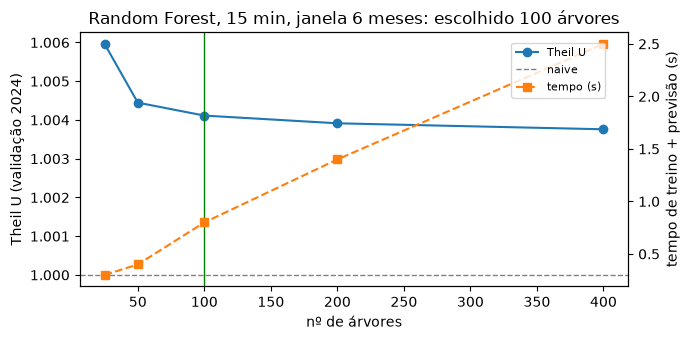

 n_arvores  tempo_s    n   RMSE    MAE  TheilU  R2_oos  acc_dir   corr
        25      0.3 9268 0.1230 0.0861  1.0060 -0.0120   0.5047 0.0063
        50      0.4 9268 0.1228 0.0859  1.0044 -0.0089   0.5088 0.0124
       100      0.8 9268 0.1227 0.0859  1.0041 -0.0082   0.5048 0.0108
       200      1.4 9268 0.1227 0.0859  1.0039 -0.0078   0.5022 0.0104
       400      2.5 9268 0.1227 0.0859  1.0038 -0.0075   0.5051 0.0111

N_ARVORES = 100


In [3]:
linhas = []
for n in [25, 50, 100, 200, 400]:
    t0 = time.time()
    prev = t.walk_forward(df15, t.features()[FEATS], rf(n), *t.VALIDACAO, janela_meses=6)
    linhas.append(dict(n_arvores=n, tempo_s=round(time.time() - t0, 1), **t.metricas(prev)))
arv = pd.DataFrame(linhas)
arv.to_csv(f"{SAIDA}/arvores_val.csv", index=False)

ref = arv.TheilU.iloc[-1]
N_ARVORES = int(arv.loc[(arv.TheilU - ref).abs() < 0.0005, "n_arvores"].min())

fig, ax1 = plt.subplots(figsize=(7, 3.5))
ax1.plot(arv.n_arvores, arv.TheilU, "o-", color="tab:blue", label="Theil U")
ax1.axhline(1, color="gray", ls="--", lw=1, label="naive")
ax1.set_xlabel("nº de árvores"); ax1.set_ylabel("Theil U (validação 2024)")
ax2 = ax1.twinx()
ax2.plot(arv.n_arvores, arv.tempo_s, "s--", color="tab:orange", label="tempo (s)")
ax2.set_ylabel("tempo de treino + previsão (s)")
ax1.axvline(N_ARVORES, color="green", lw=1)
ax1.set_title(f"Random Forest, 15 min, janela 6 meses: escolhido {N_ARVORES} árvores")
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.88), fontsize=8)
fig.tight_layout(); fig.savefig(f"{SAIDA}/arvores_val.png", dpi=150); plt.show()
print(arv.round(4).to_string(index=False))
print(f"\nN_ARVORES = {N_ARVORES}")

## Etapa B – Grade candle × janela (validação 2024)

Random Forest com hiperparâmetros fixos nas 12 combinações (candle 1/15/60 min × janela 1/3/6/12 meses), re-treino trimestral. A esperança é a de operar em todo candle, com custo de 5 pontos; `t_stat` mostra se ela é distinguível de zero. `n_treino` é o tamanho da janela de treino do 1º trimestre (as janelas de 3 e 6 meses coincidem aí por causa do buraco jun–out/2023 na base) e `min_leaf` o tamanho mínimo da folha resultante.

In [4]:
FABRICA = rf(N_ARVORES)
tab = t.rodar_grade(win, wdo, MODELO, FABRICA, FEATS, SAIDA)

extra = []
for r in tab.itertuples():
    df_c = BASES[r.candle][0]
    ini = pd.Timestamp(t.VALIDACAO[0])
    n_tr = ((df_c.index >= ini - pd.DateOffset(months=r.janela_meses)) & (df_c.index < ini)).sum()
    prev = pd.read_csv(f"{SAIDA}/previsoes/WIN_{r.candle}_{r.janela_meses}m_{MODELO}_val.csv", index_col=0, parse_dates=True)
    st = estat(t.simular(prev, custo_pts=5))
    extra.append(dict(n_treino=n_tr, min_leaf=max(FOLHA_MIN, int(FOLHA_FRAC * n_tr)),
                      n_previsoes_distintas=prev.y_pred.round(8).nunique(),
                      sim_ep_pts=st["ep_pts"], sim_t_stat=st["t_stat"]))
tab = pd.concat([tab, pd.DataFrame(extra)], axis=1)
tab.to_csv(f"{SAIDA}/grade_val.csv", index=False)

t.heatmap(tab, "TheilU", f"{MODELO}: Theil U (validação 2024)", f"{SAIDA}/heatmap_theilU.png", menor_melhor=True)
t.heatmap(tab, "acc_dir", f"{MODELO}: acurácia direcional", f"{SAIDA}/heatmap_acuracia.png", fmt=".3f")
t.heatmap(tab, "sim_esperanca_pts", f"{MODELO}: esperança por operação (pts)", f"{SAIDA}/heatmap_esperanca.png", fmt=".2f")
cols = ["candle", "janela_meses", "n_treino", "min_leaf", "n_previsoes_distintas", "tempo_s", "TheilU", "R2_oos",
        "acc_dir", "sim_n_ops", "sim_esperanca_pts", "sim_ep_pts", "sim_t_stat", "sim_fator_lucro"]
tab[cols].round(4)

rf 1min 1m {'n': 141216.0, 'RMSE': 0.0327, 'MAE': 0.0228, 'TheilU': 1.0015, 'R2_oos': -0.0029, 'acc_dir': 0.5029, 'corr': 0.0033} 2s


rf 1min 3m {'n': 141216.0, 'RMSE': 0.0327, 'MAE': 0.0227, 'TheilU': 1.0006, 'R2_oos': -0.0012, 'acc_dir': 0.5063, 'corr': 0.0024} 5s


rf 1min 6m {'n': 141216.0, 'RMSE': 0.0327, 'MAE': 0.0227, 'TheilU': 1.0004, 'R2_oos': -0.0007, 'acc_dir': 0.5083, 'corr': 0.0056} 11s


rf 1min 12m {'n': 141216.0, 'RMSE': 0.0327, 'MAE': 0.0227, 'TheilU': 1.0, 'R2_oos': -0.0001, 'acc_dir': 0.5079, 'corr': 0.0118} 32s


rf 15min 1m {'n': 9268.0, 'RMSE': 0.1239, 'MAE': 0.0867, 'TheilU': 1.0133, 'R2_oos': -0.0268, 'acc_dir': 0.5067, 'corr': 0.0084} 1s


rf 15min 3m {'n': 9268.0, 'RMSE': 0.123, 'MAE': 0.086, 'TheilU': 1.0063, 'R2_oos': -0.0126, 'acc_dir': 0.503, 'corr': -0.0048} 1s


... (3 outputs left out)

rf 60min 3m {'n': 2254.0, 'RMSE': 0.2328, 'MAE': 0.1649, 'TheilU': 1.018, 'R2_oos': -0.0364, 'acc_dir': 0.4875, 'corr': -0.0139} 1s


rf 60min 6m {'n': 2254.0, 'RMSE': 0.2324, 'MAE': 0.1644, 'TheilU': 1.0164, 'R2_oos': -0.0331, 'acc_dir': 0.4937, 'corr': -0.0217} 1s


rf 60min 12m {'n': 2254.0, 'RMSE': 0.2307, 'MAE': 0.163, 'TheilU': 1.009, 'R2_oos': -0.0181, 'acc_dir': 0.509, 'corr': 0.0081} 1s


,candle,janela_meses,n_treino,min_leaf,n_previsoes_distintas,tempo_s,TheilU,R2_oos,acc_dir,sim_n_ops,sim_esperanca_pts,sim_ep_pts,sim_t_stat,sim_fator_lucro
0,1min,1,10702,107,121304,1.9,1.0015,-0.0029,0.5029,141216,-4.8787,0.1121,-43.5223,0.7172
1,1min,3,27318,273,109644,5.2,1.0006,-0.0012,0.5063,141216,-4.8098,0.1121,-42.9079,0.7204
2,1min,6,27318,273,106197,10.6,1.0004,-0.0007,0.5083,141216,-4.6652,0.1121,-41.6181,0.7275
3,1min,12,84569,845,98115,31.7,1.0000,-0.0001,0.5079,141216,-4.7872,0.1121,-42.7064,0.7214
4,15min,1,703,10,9260,1.1,1.0133,-0.0268,0.5067,9268,-4.7427,1.6364,-2.8983,0.9175
5,15min,3,1793,17,9262,1.2,1.0063,-0.0126,0.5030,9268,-4.6261,1.6364,-2.8271,0.9195
6,15min,6,1793,17,9258,1.3,1.0041,-0.0082,0.5048,9268,-4.3995,1.6364,-2.6886,0.9232
7,15min,12,5548,55,9243,1.7,1.0025,-0.0050,0.4977,9268,-5.4580,1.6364,-3.3355,0.9057
8,60min,1,171,10,2254,0.8,1.0237,-0.0479,0.5130,2254,1.0293,6.2029,0.1659,1.0099
9,60min,3,430,10,2254,0.8,1.0180,-0.0364,0.4875,2254,-10.9716,6.2030,-1.7688,0.9000


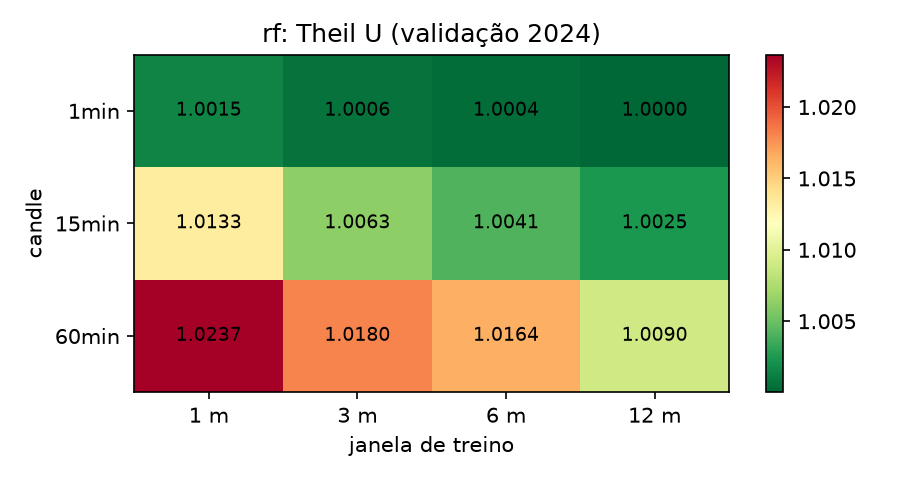

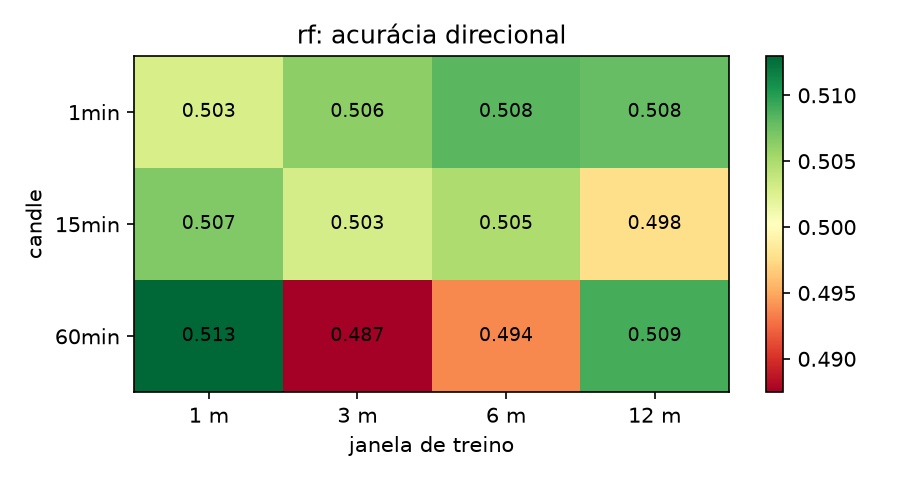

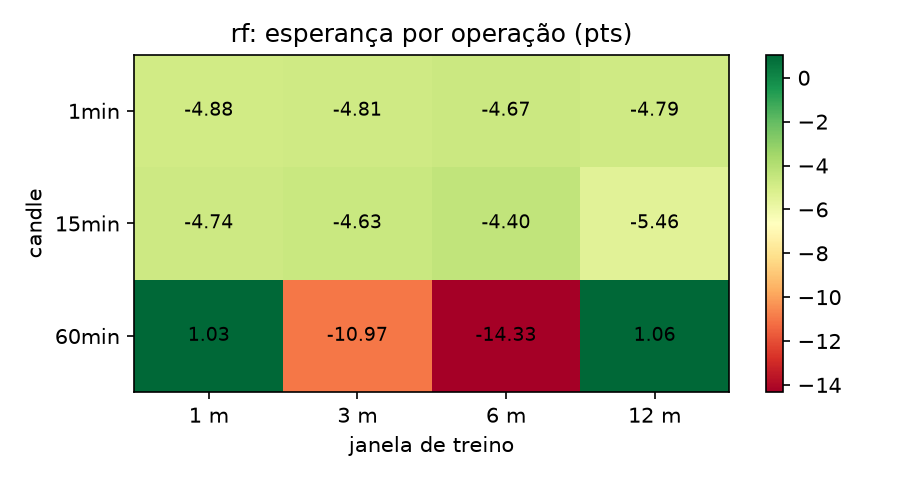

Critério: nenhuma com t ≥ 2: menor Theil U
Melhor combinação: candle 1min, janela 12 meses | Theil U 1.0000 | acurácia 50.8% | esperança -4.79 pts/op (t = -42.71)
Combinações com Theil U < 1: 0 de 12


In [5]:
from IPython.display import Image, display
for h in ["heatmap_theilU", "heatmap_acuracia", "heatmap_esperanca"]:
    display(Image(f"{SAIDA}/{h}.png"))

melhor, CRITERIO_GRADE = escolher_linha(tab, "sim_esperanca_pts", "sim_t_stat")
CANDLE, JANELA = melhor.candle, int(melhor.janela_meses)
print(f"Critério: {CRITERIO_GRADE}")
print(f"Melhor combinação: candle {CANDLE}, janela {JANELA} {'mês' if JANELA == 1 else 'meses'} | Theil U {melhor.TheilU:.4f} | "
      f"acurácia {melhor.acc_dir:.1%} | esperança {melhor.sim_esperanca_pts:.2f} pts/op (t = {melhor.sim_t_stat:.2f})")
print(f"Combinações com Theil U < 1: {(tab.TheilU < 1).sum()} de {len(tab)}")

## Etapa C – Regra de operação (validação 2024)

Na melhor combinação: 4 limiares × 3 take profits × 3 stop losses = 36 regras, custo de 5 pontos. Escolhe a de maior esperança **entre as que têm t ≥ 2**; se nenhuma, a regra padrão.

In [6]:
prev_val = pd.read_csv(f"{SAIDA}/previsoes/WIN_{CANDLE}_{JANELA}m_{MODELO}_val.csv", index_col=0, parse_dates=True)
regras = regras_com_t(prev_val, custo_pts=5)
regras.to_csv(f"{SAIDA}/regras_val.csv", index=False)
regra, CRITERIO_REGRA = escolher_regra(regras)
print(f"Critério: {CRITERIO_REGRA}")
regras.head(10)[["limiar_q", "tp_mult", "sl_mult", "n_ops", "taxa_acerto", "payoff", "esperanca_pts", "ep_pts",
                 "t_stat", "fator_lucro", "resultado_R"]].round(3)

Critério: nenhuma regra com t ≥ 2: regra padrão (opera sempre, sem TP/SL)


,limiar_q,tp_mult,sl_mult,n_ops,taxa_acerto,payoff,esperanca_pts,ep_pts,t_stat,fator_lucro,resultado_R
0,0.90,1.0,NaN,14122,0.539,0.668,-3.495,0.430,-8.137,0.838,-9871.620
1,0.90,NaN,NaN,14122,0.453,0.938,-3.883,0.535,-7.256,0.842,-10966.000
2,0.90,2.0,NaN,14122,0.462,0.898,-3.979,0.495,-8.037,0.835,-11237.416
3,0.75,1.0,NaN,35304,0.503,0.721,-4.081,0.242,-16.840,0.793,-28817.375
4,0.90,NaN,2.0,14122,0.447,0.950,-4.181,0.488,-8.565,0.829,-11810.098
5,0.90,NaN,1.0,14122,0.398,1.159,-4.261,0.430,-9.915,0.813,-12033.818
6,0.75,2.0,NaN,35304,0.444,0.913,-4.334,0.275,-15.773,0.798,-30602.251
7,0.75,NaN,NaN,35304,0.438,0.932,-4.450,0.292,-15.220,0.796,-31421.000
8,0.50,1.0,NaN,70608,0.468,0.771,-4.452,0.153,-29.190,0.750,-62874.836
9,0.90,2.0,2.0,14122,0.453,0.909,-4.532,0.458,-9.901,0.813,-12799.614


## Etapa D – Variante

Na melhor combinação candle × janela:
1. **Hiperparâmetros:** `max_depth ∈ {4, 8, 12}` × folha mínima de `{0,5%, 2%}` das linhas de treino (6 combinações), além do modelo base (8, 1%).
2. **Árvore simples** (`DecisionTreeRegressor`, mesma profundidade e folha do base), para comparar desempenho e tempo com a floresta.
3. **Importância das features** do modelo final.

Cada variante é avaliada com a sua regra escolhida pelo mesmo critério da Etapa C. A variante final é a de maior esperança com t ≥ 2; se nenhuma, a de menor Theil U.

In [7]:
dfb, sb = BASES[CANDLE]
X_cols = t.features()[FEATS]

def avaliar(nome, fabrica):
    t0 = time.time()
    prev = t.walk_forward(dfb, X_cols, fabrica, *t.VALIDACAO, janela_meses=JANELA)
    seg = time.time() - t0
    g = regras_com_t(prev, custo_pts=5)
    r, _ = escolher_regra(g)
    tp_ = None if pd.isna(r.tp_mult) else r.tp_mult
    sl_ = None if pd.isna(r.sl_mult) else r.sl_mult
    ops = t.simular(prev, r.limiar, tp_, sl_, 5)
    return dict(variante=nome, candle=CANDLE, janela_meses=JANELA, tempo_s=round(seg, 2), **t.metricas(prev),
                limiar_q=r.limiar_q, limiar=r.limiar, tp_mult=tp_, sl_mult=sl_,
                **{f"sim_{k}": v for k, v in t.resumo_operacoes(ops).items()},
                **{f"sim_{k}": v for k, v in estat(ops).items() if k != "esperanca_pts"})

VARIANTES = {f"rf_d{d}_f{f:g}": rf(N_ARVORES, d, f / 100) for d in [4, 8, 12] for f in [0.5, 2]}
VARIANTES["rf_base_d8_f1"] = FABRICA
VARIANTES["arvore_d8_f1"] = lambda: FolhaProporcional(DecisionTreeRegressor(max_depth=8, random_state=42))

var = pd.DataFrame([avaliar(n, f) for n, f in VARIANTES.items()]).sort_values("sim_esperanca_pts", ascending=False)
var.to_csv(f"{SAIDA}/variante_val.csv", index=False)
var[["variante", "tempo_s", "TheilU", "R2_oos", "acc_dir", "limiar_q", "tp_mult", "sl_mult",
     "sim_n_ops", "sim_esperanca_pts", "sim_ep_pts", "sim_t_stat", "sim_fator_lucro"]].round(4)

,variante,tempo_s,TheilU,R2_oos,acc_dir,limiar_q,tp_mult,sl_mult,sim_n_ops,sim_esperanca_pts,sim_ep_pts,sim_t_stat,sim_fator_lucro
1,rf_d4_f2,14.78,1.0000,0.0001,0.5093,0.0,None,None,141216,-4.7105,0.1121,-42.0227,0.7251
6,rf_base_d8_f1,26.42,1.0000,-0.0001,0.5079,0.0,None,None,141216,-4.7872,0.1121,-42.7064,0.7214
0,rf_d4_f0.5,14.71,1.0000,-0.0000,0.5075,0.0,None,None,141216,-4.7917,0.1121,-42.7462,0.7212
5,rf_d12_f2,27.01,1.0000,-0.0001,0.5073,0.0,None,None,141216,-4.7994,0.1121,-42.8150,0.7208
3,rf_d8_f2,18.12,1.0000,-0.0000,0.5078,0.0,None,None,141216,-4.8057,0.1121,-42.8712,0.7205
2,rf_d8_f0.5,23.96,1.0001,-0.0002,0.5078,0.0,None,None,141216,-4.8146,0.1121,-42.9502,0.7200
4,rf_d12_f0.5,37.84,1.0001,-0.0002,0.5080,0.0,None,None,141216,-4.8425,0.1121,-43.1989,0.7186
7,arvore_d8_f1,6.32,1.0012,-0.0024,0.5027,0.0,None,None,141216,-4.9282,0.1121,-43.9631,0.7148


Critério: nenhuma com t ≥ 2: menor Theil U
Modelo final: rf_d4_f2 | Theil U 1.0000 | esperança -4.71 pts/op (t = -42.02)
Tempo: floresta base 26.42s × árvore simples 6.32s | Theil U: floresta 1.0000 × árvore 1.0012


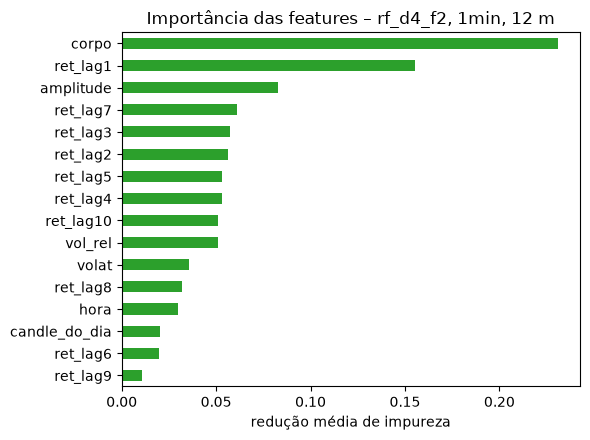

In [8]:
# modelo final da frente: a melhor variante de RF (a árvore simples é só referência)
final, CRITERIO_VAR = escolher_linha(var[var.variante.str.startswith("rf_")], "sim_esperanca_pts", "sim_t_stat")
MODELO_FINAL = final.variante
FABRICA_FINAL = VARIANTES[MODELO_FINAL]
if MODELO_FINAL != "rf_base_d8_f1":
    regra = final            # regra escolhida para a variante vencedora
arvore = var[var.variante == "arvore_d8_f1"].iloc[0]
base = var[var.variante == "rf_base_d8_f1"].iloc[0]
print(f"Critério: {CRITERIO_VAR}")
print(f"Modelo final: {MODELO_FINAL} | Theil U {final.TheilU:.4f} | esperança {final.sim_esperanca_pts:.2f} pts/op (t = {final.sim_t_stat:.2f})")
print(f"Tempo: floresta base {base.tempo_s:.2f}s × árvore simples {arvore.tempo_s:.2f}s "
      f"| Theil U: floresta {base.TheilU:.4f} × árvore {arvore.TheilU:.4f}")

# importância das features: modelo final treinado na última janela da validação
ini = pd.Timestamp("2024-10-01")
tr = dfb[(dfb.index >= ini - pd.DateOffset(months=JANELA)) & (dfb.index < ini)].iloc[:-1]
m = FABRICA_FINAL().fit(tr[X_cols], tr["alvo"])
imp = pd.Series(m.m.feature_importances_, index=X_cols).sort_values()
fig, ax = plt.subplots(figsize=(6, 4.5))
imp.plot.barh(ax=ax, color="tab:green")
ax.set_title(f"Importância das features – {MODELO_FINAL}, {CANDLE}, {JANELA} m"); ax.set_xlabel("redução média de impureza")
fig.tight_layout(); fig.savefig(f"{SAIDA}/importancia_features.png", dpi=150); plt.show()

## Etapa E – Congelamento e teste (01/2025 → 03/2026)

**Rodado uma única vez.** Depois desta célula, nada volta a ser ajustado.

In [9]:
tp = None if pd.isna(regra.tp_mult) else float(regra.tp_mult)
sl = None if pd.isna(regra.sl_mult) else float(regra.sl_mult)
config = dict(frente=FRENTE, modelo=MODELO_FINAL, n_arvores=N_ARVORES, folha_frac=FOLHA_FRAC, folha_min=FOLHA_MIN,
              candle=CANDLE, janela_meses=JANELA, limiar_q=float(regra.limiar_q), limiar=float(regra.limiar),
              tp_mult=tp, sl_mult=sl, custo_escolha_pts=5, t_min=T_MIN,
              criterio_grade=CRITERIO_GRADE, criterio_regra=CRITERIO_REGRA, criterio_variante=CRITERIO_VAR)
json.dump(config, open(f"{SAIDA}/config_final.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)
print(json.dumps(config, indent=2, ensure_ascii=False))

prev_teste = t.walk_forward(dfb, X_cols, FABRICA_FINAL, *t.TESTE, janela_meses=JANELA)
prev_teste.to_csv(f"{SAIDA}/previsoes/WIN_{CANDLE}_{JANELA}m_{MODELO}_teste.csv")

aleat = t.sinais_aleatorios(prev_teste)
linhas = []
for custo in t.CUSTOS_PTS:
    ops_m = t.simular(prev_teste, regra.limiar, tp, sl, custo)
    ops_a = t.simular(aleat, 0, tp, sl, custo)
    linhas.append(dict(serie="modelo", custo_pts=custo, **t.metricas(prev_teste), cw_t=clark_west(prev_teste),
                       **t.resumo_operacoes(ops_m),
                       **{k: v for k, v in estat(ops_m).items() if k != "esperanca_pts"}))
    linhas.append(dict(serie="aleatorio", custo_pts=custo, **t.resumo_operacoes(ops_a),
                       **{k: v for k, v in estat(ops_a).items() if k != "esperanca_pts"}))
teste = pd.DataFrame(linhas)
teste.to_csv(f"{SAIDA}/teste_final.csv", index=False)
teste[["serie", "custo_pts", "TheilU", "R2_oos", "cw_t", "acc_dir", "n_ops", "taxa_acerto", "payoff", "esperanca_pts",
       "ep_pts", "t_stat", "fator_lucro", "resultado_R", "drawdown_max_pts"]].round(4)

{
  "frente": "ml",
  "modelo": "rf_d4_f2",
  "n_arvores": 100,
  "folha_frac": 0.01,
  "folha_min": 10,
  "candle": "1min",
  "janela_meses": 12,
  "limiar_q": 0.0,
  "limiar": 0.0,
  "tp_mult": null,
  "sl_mult": null,
  "custo_escolha_pts": 5,
  "t_min": 2.0,
  "criterio_grade": "nenhuma com t ≥ 2: menor Theil U",
  "criterio_regra": "nenhuma regra com t ≥ 2: regra padrão (opera sempre, sem TP/SL)",
  "criterio_variante": "nenhuma com t ≥ 2: menor Theil U"
}


,serie,custo_pts,TheilU,R2_oos,cw_t,acc_dir,n_ops,taxa_acerto,payoff,esperanca_pts,ep_pts,t_stat,fator_lucro,resultado_R,drawdown_max_pts
0,modelo,0,0.9999,0.0002,3.7212,0.5137,174579,0.4840,0.9743,0.5896,0.1531,3.8523,1.0294,20587.0,23180.0
1,aleatorio,0,NaN,NaN,NaN,NaN,174579,0.4705,1.0104,0.1680,0.1531,1.0974,1.0083,5865.0,19290.0
2,modelo,5,0.9999,0.0002,3.7212,0.5137,174579,0.4260,0.9757,-4.4104,0.1531,-28.8157,0.8054,-153992.0,770500.0
3,aleatorio,5,NaN,NaN,NaN,NaN,174579,0.4149,1.0075,-4.8320,0.1531,-31.5693,0.7894,-168714.0,848365.0
4,modelo,10,0.9999,0.0002,3.7212,0.5137,174579,0.3715,0.9757,-9.4104,0.1531,-61.4838,0.6315,-328571.0,1643160.0
5,aleatorio,10,NaN,NaN,NaN,NaN,174579,0.3623,1.0013,-9.8320,0.1531,-64.2361,0.6199,-343293.0,1718370.0


## Etapa F – Gráficos finais e resumo

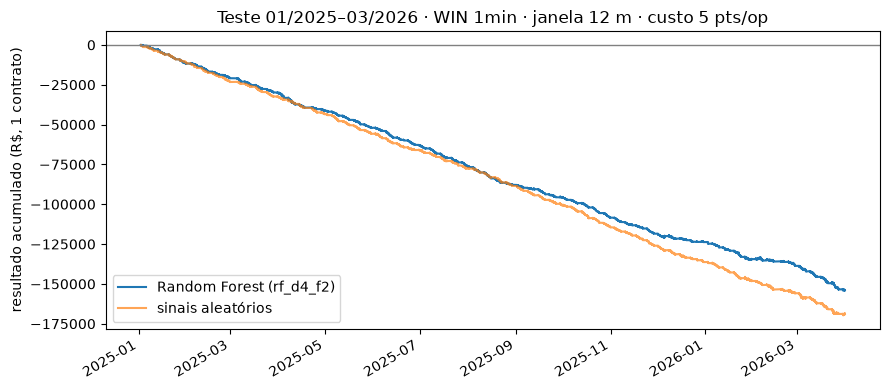

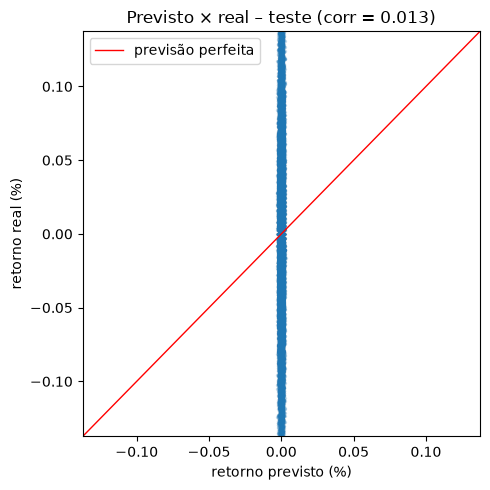

In [10]:
ops_m = t.simular(prev_teste, regra.limiar, tp, sl, 5)
ops_a = t.simular(aleat, 0, tp, sl, 5)
fig, ax = plt.subplots(figsize=(9, 4))
(ops_m.pontos.cumsum() * t.PONTO_WIN).plot(ax=ax, label=f"Random Forest ({MODELO_FINAL})")
(ops_a.pontos.cumsum() * t.PONTO_WIN).plot(ax=ax, label="sinais aleatórios", alpha=0.7)
ax.axhline(0, color="gray", lw=1)
ax.set_ylabel("resultado acumulado (R$, 1 contrato)"); ax.set_xlabel("")
ax.set_title(f"Teste 01/2025–03/2026 · WIN {CANDLE} · janela {JANELA} m · custo 5 pts/op")
ax.legend(); fig.tight_layout(); fig.savefig(f"{SAIDA}/curva_capital_teste.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(prev_teste.y_pred, prev_teste.y_true, s=2, alpha=0.2)
lim = np.quantile(np.abs(prev_teste.y_true), 0.99)
ax.plot([-lim, lim], [-lim, lim], color="red", lw=1, label="previsão perfeita")
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel("retorno previsto (%)"); ax.set_ylabel("retorno real (%)")
ax.set_title(f"Previsto × real – teste (corr = {prev_teste.y_true.corr(prev_teste.y_pred):.3f})")
ax.legend(); fig.tight_layout(); fig.savefig(f"{SAIDA}/previsto_vs_real_teste.png", dpi=150); plt.show()

In [11]:
tm = teste[teste.serie == "modelo"].set_index("custo_pts")
ta = teste[teste.serie == "aleatorio"].set_index("custo_pts")
cw = tm.loc[5, "cw_t"]
if cw > 1.645:
    bate = (f"a previsão é estatisticamente melhor que o naive (Clark-West t = {cw:.2f}), "
            f"mas o ganho é minúsculo: o erro cai {(1 - tm.loc[5, 'TheilU']) * 100:.2f}%")
else:
    bate = f"o modelo não bate o naive (Clark-West t = {cw:.2f})"
lucro = "positiva" if tm.loc[5, "esperanca_pts"] > 0 and tm.loc[5, "fator_lucro"] > 1 else "negativa"
corr_acc_esp = tab[["acc_dir", "sim_esperanca_pts"]].corr().iloc[0, 1]
top_feats = ", ".join(imp.sort_values(ascending=False).index[:3])
desc = lambda x: "sem" if x is None else f"{x:g}× a volatilidade"
regra_txt = (f"opera quando |previsão| passa o quantil {regra.limiar_q:.0%}, take profit {desc(tp)}, "
             f"stop loss {desc(sl)}. Critério: {CRITERIO_REGRA}")
n_sig = int(((tab.sim_esperanca_pts > 0) & (tab.sim_t_stat >= T_MIN)).sum())
jan_txt = f"{JANELA} {'mês' if JANELA == 1 else 'meses'}"
prof_final, folha_final = (8, FOLHA_FRAC * 100) if MODELO_FINAL == "rf_base_d8_f1" else (
    int(MODELO_FINAL.split("_d")[1].split("_")[0]), float(MODELO_FINAL.split("_f")[1]))

resumo = f'''# Resumo – Frente de ML (Random Forest)

- **Q1 – Melhor candle e janela:** {CANDLE} com {jan_txt} de treino. Critério: {CRITERIO_GRADE} ({n_sig} de {len(tab)} combinações tiveram esperança positiva com t ≥ 2 na validação 2024). Modelo final: `{MODELO_FINAL}` com {N_ARVORES} árvores, profundidade {prof_final} e folha mínima de {folha_final:g}% do treino.
- **Q2 – Bate o naive?** No teste, Theil U = {tm.loc[5, "TheilU"]:.4f} e R²_oos = {tm.loc[5, "R2_oos"]:.4f}: {bate}. Na validação, {(tab.TheilU < 1).sum()} de {len(tab)} combinações tiveram Theil U < 1.
- **Q3 – Acertar mais é ganhar mais?** Na grade, a correlação entre acurácia direcional e esperança foi {corr_acc_esp:.2f}. No teste, a taxa de acerto das operações foi {tm.loc[5, "taxa_acerto"]:.1%} com payoff {tm.loc[5, "payoff"]:.2f}.
- **Q4 – Regra e resultado no teste:** {regra_txt}. Esperança {lucro}: {tm.loc[0, "esperanca_pts"]:.2f} / {tm.loc[5, "esperanca_pts"]:.2f} / {tm.loc[10, "esperanca_pts"]:.2f} pts por operação com custo 0 / 5 / 10 pts (t = {tm.loc[5, "t_stat"]:.2f} com 5 pts; aleatório: {ta.loc[5, "esperanca_pts"]:.2f}). Resultado com 5 pts: R$ {tm.loc[5, "resultado_R"]:,.0f} em {int(tm.loc[5, "n_ops"])} operações.
- **Observação:** as features mais usadas foram {top_feats}. A árvore simples teve Theil U {arvore.TheilU:.4f} contra {base.TheilU:.4f} da floresta base, em {arvore.tempo_s:.2f}s contra {base.tempo_s:.2f}s.
'''
open(f"{SAIDA}/resumo.md", "w", encoding="utf-8").write(resumo)
print(resumo)

# Resumo – Frente de ML (Random Forest)

- **Q1 – Melhor candle e janela:** 1min com 12 meses de treino. Critério: nenhuma com t ≥ 2: menor Theil U (0 de 12 combinações tiveram esperança positiva com t ≥ 2 na validação 2024). Modelo final: `rf_d4_f2` com 100 árvores, profundidade 4 e folha mínima de 2% do treino.
- **Q2 – Bate o naive?** No teste, Theil U = 0.9999 e R²_oos = 0.0002: a previsão é estatisticamente melhor que o naive (Clark-West t = 3.72), mas o ganho é minúsculo: o erro cai 0.01%. Na validação, 0 de 12 combinações tiveram Theil U < 1.
- **Q3 – Acertar mais é ganhar mais?** Na grade, a correlação entre acurácia direcional e esperança foi 0.85. No teste, a taxa de acerto das operações foi 42.6% com payoff 0.98.
- **Q4 – Regra e resultado no teste:** opera quando |previsão| passa o quantil 0%, take profit sem, stop loss sem. Critério: nenhuma regra com t ≥ 2: regra padrão (opera sempre, sem TP/SL). Esperança negativa: 0.59 / -4.41 / -9.41 pts por operação com custo 0 / 5 / 